# Movie Review Sentiment Analysis (Local Re-run)

> This notebook is a local re-run (Python 3.13) of the main notebook, [`notebook.ipynb`](notebook.ipynb), with the same pipeline and identical test metrics. See [`docs/notebook_local.md`](docs/notebook_local.md) for the differences.

The Film Junky Union, a new community for classic movie enthusiasts, is developing a system to filter and categorize movie reviews. The goal is to train a model that automatically detects negative reviews, using a dataset of IMDB movie reviews labeled by polarity to classify reviews as positive or negative.

**Success criterion:** an F1-score of at least **0.85** on the test set.

## Setup

In [ ]:
# import math
import numpy as np
import pandas as pd
# import matplotlib
import matplotlib.pyplot as plt
# import matplotlib.dates as mdates
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.dummy import DummyClassifier
# import nltk
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import unicodedata
from nltk.corpus import stopwords
import spacy
from lightgbm import LGBMClassifier
# import torch
# import transformers
# import re
import sklearn.metrics as metrics

c:\Users\luiiz\OneDrive\Documentos\TripleTen\Sprint14\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# the next line provides higher-quality charts on HiDPI screens
%config InlineBackend.figure_format = 'retina'

plt.style.use('seaborn-v0_8')

In [3]:
# enables progress_apply; see https://pypi.org/project/tqdm/#pandas-integration
tqdm.pandas()

## Load Data

In [4]:
df_reviews = pd.read_csv('./datasets/imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})

## Exploratory Data Analysis

Number of movies and reviews over the years.

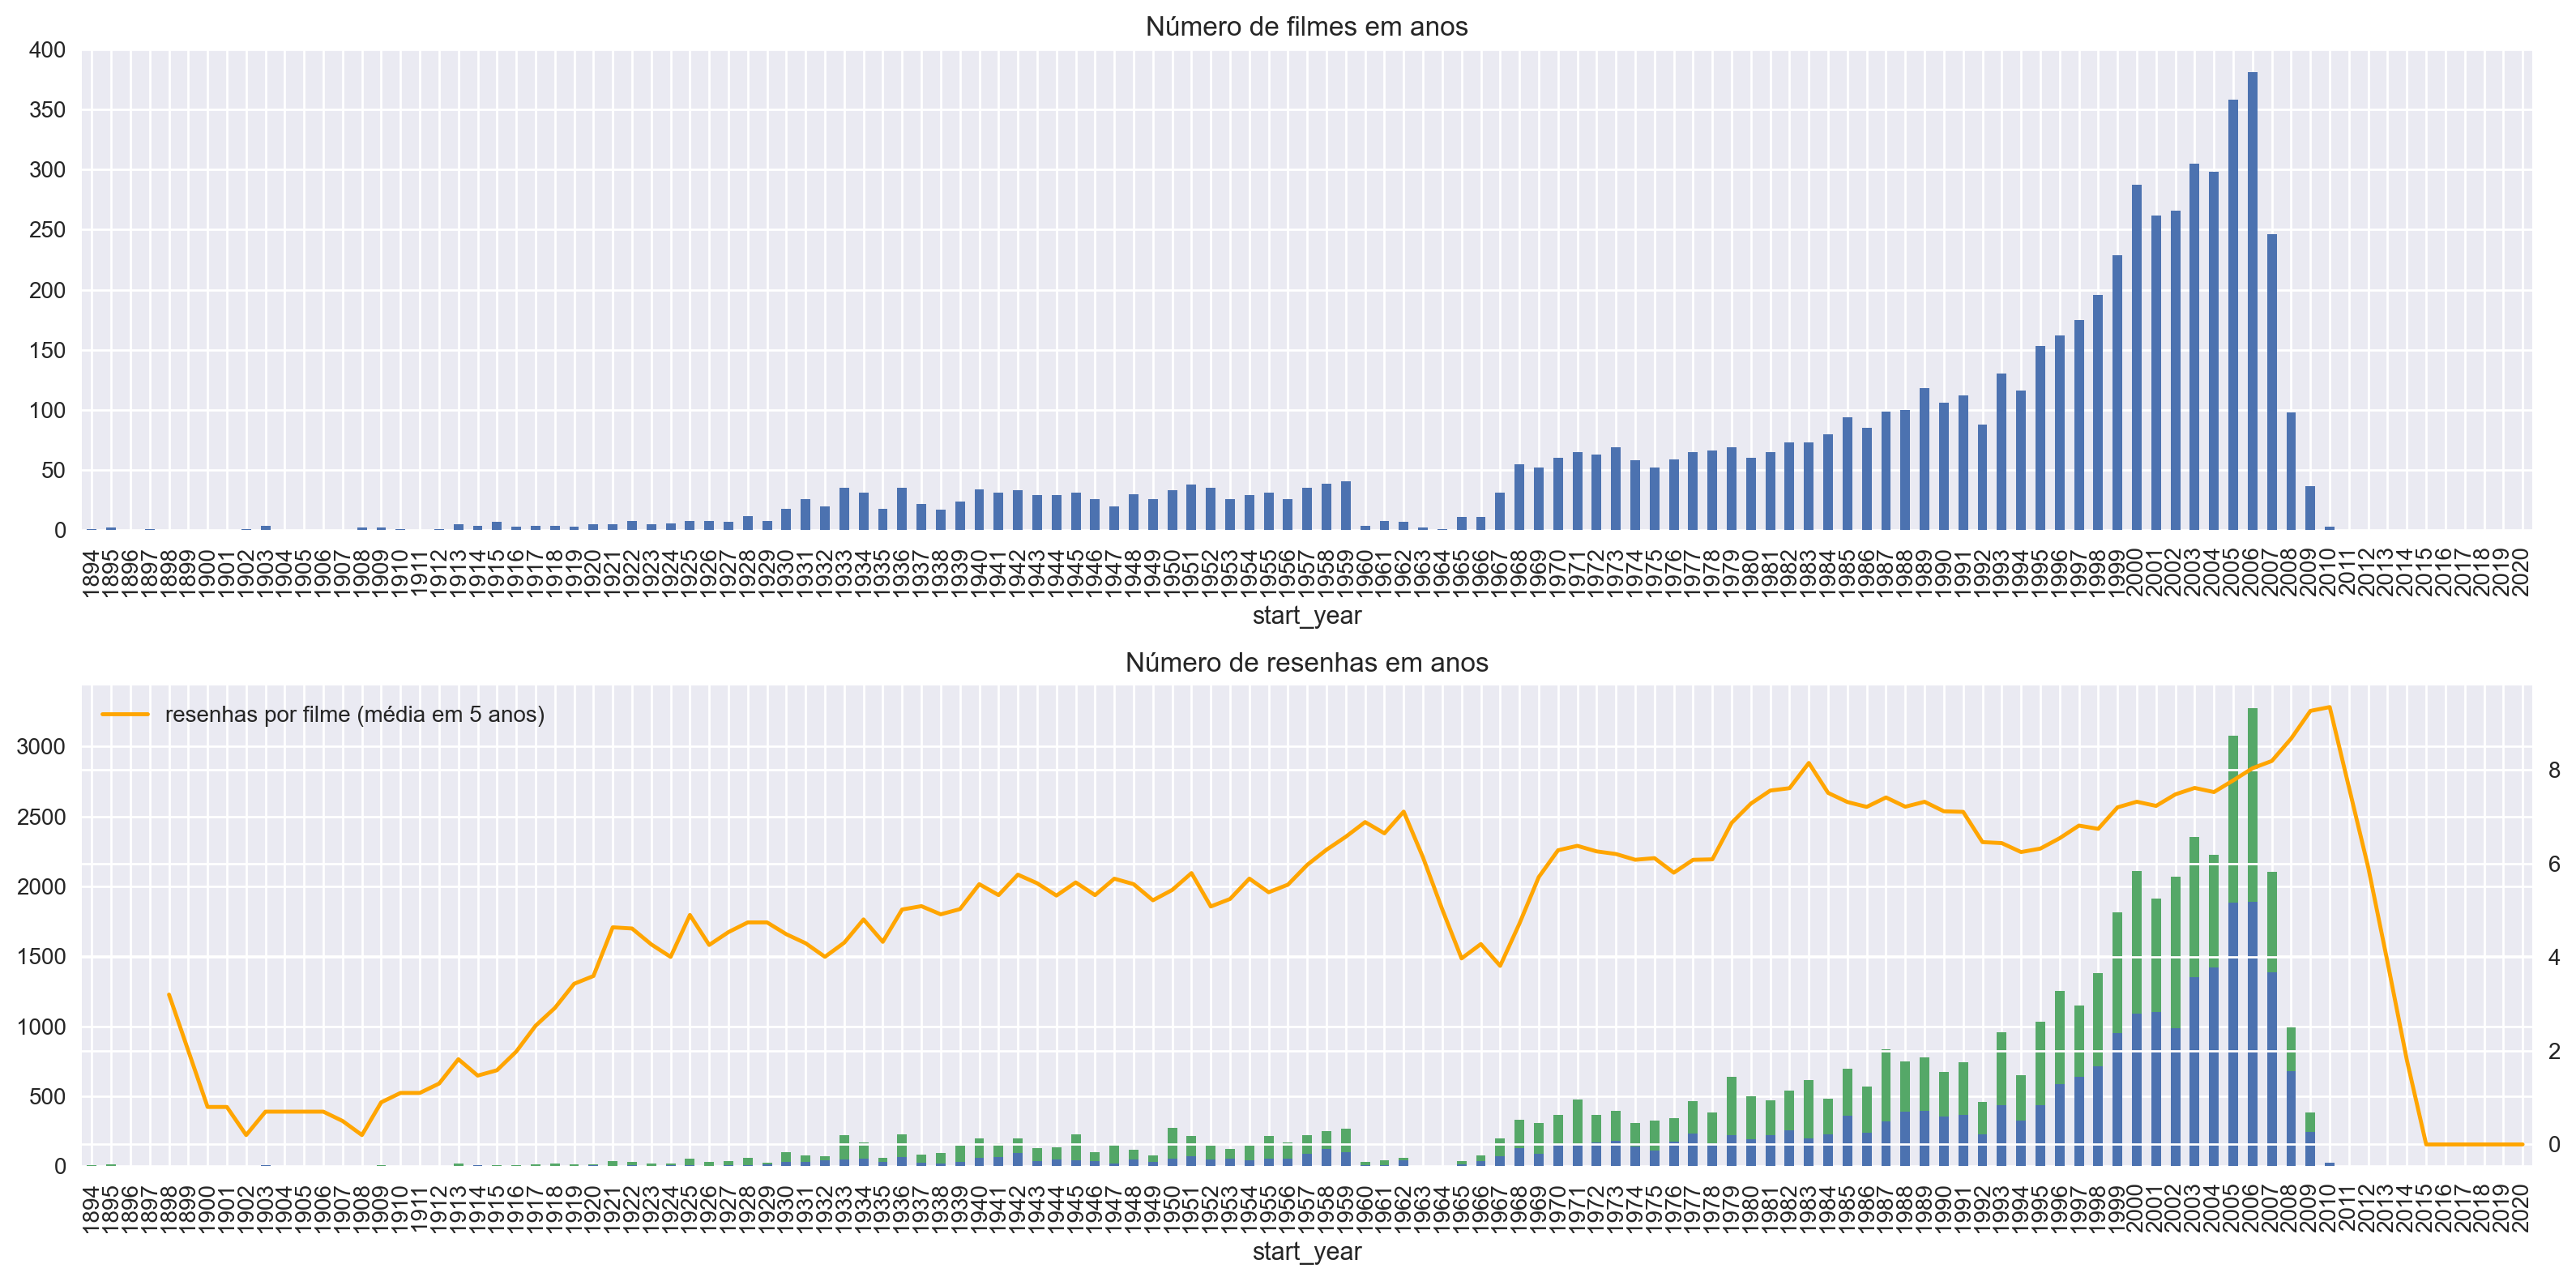

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ax = axs[0]

dft1 = df_reviews[['tconst', 'start_year']].drop_duplicates() \
    ['start_year'].value_counts().sort_index()
dft1 = dft1.reindex(index=np.arange(dft1.index.min(), max(dft1.index.max(), 2021))).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de filmes em anos')

ax = axs[1]

dft2 = df_reviews.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)

dft2.plot(kind='bar', stacked=True, label='#reviews (neg, pos)', ax=ax)

dft2 = df_reviews['start_year'].value_counts().sort_index()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)
dft3 = (dft2/dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(color='orange', label='resenhas por filme (média em 5 anos)', ax=axt)

lines, labels = axt.get_legend_handles_labels()
ax.legend(lines, labels, loc='upper left')

ax.set_title('Número de resenhas em anos')

fig.tight_layout()

Distribution of the number of reviews per movie, shown both as exact counts and as a KDE (kernel density estimate), to see how the smoothed estimate differs from the exact counts.

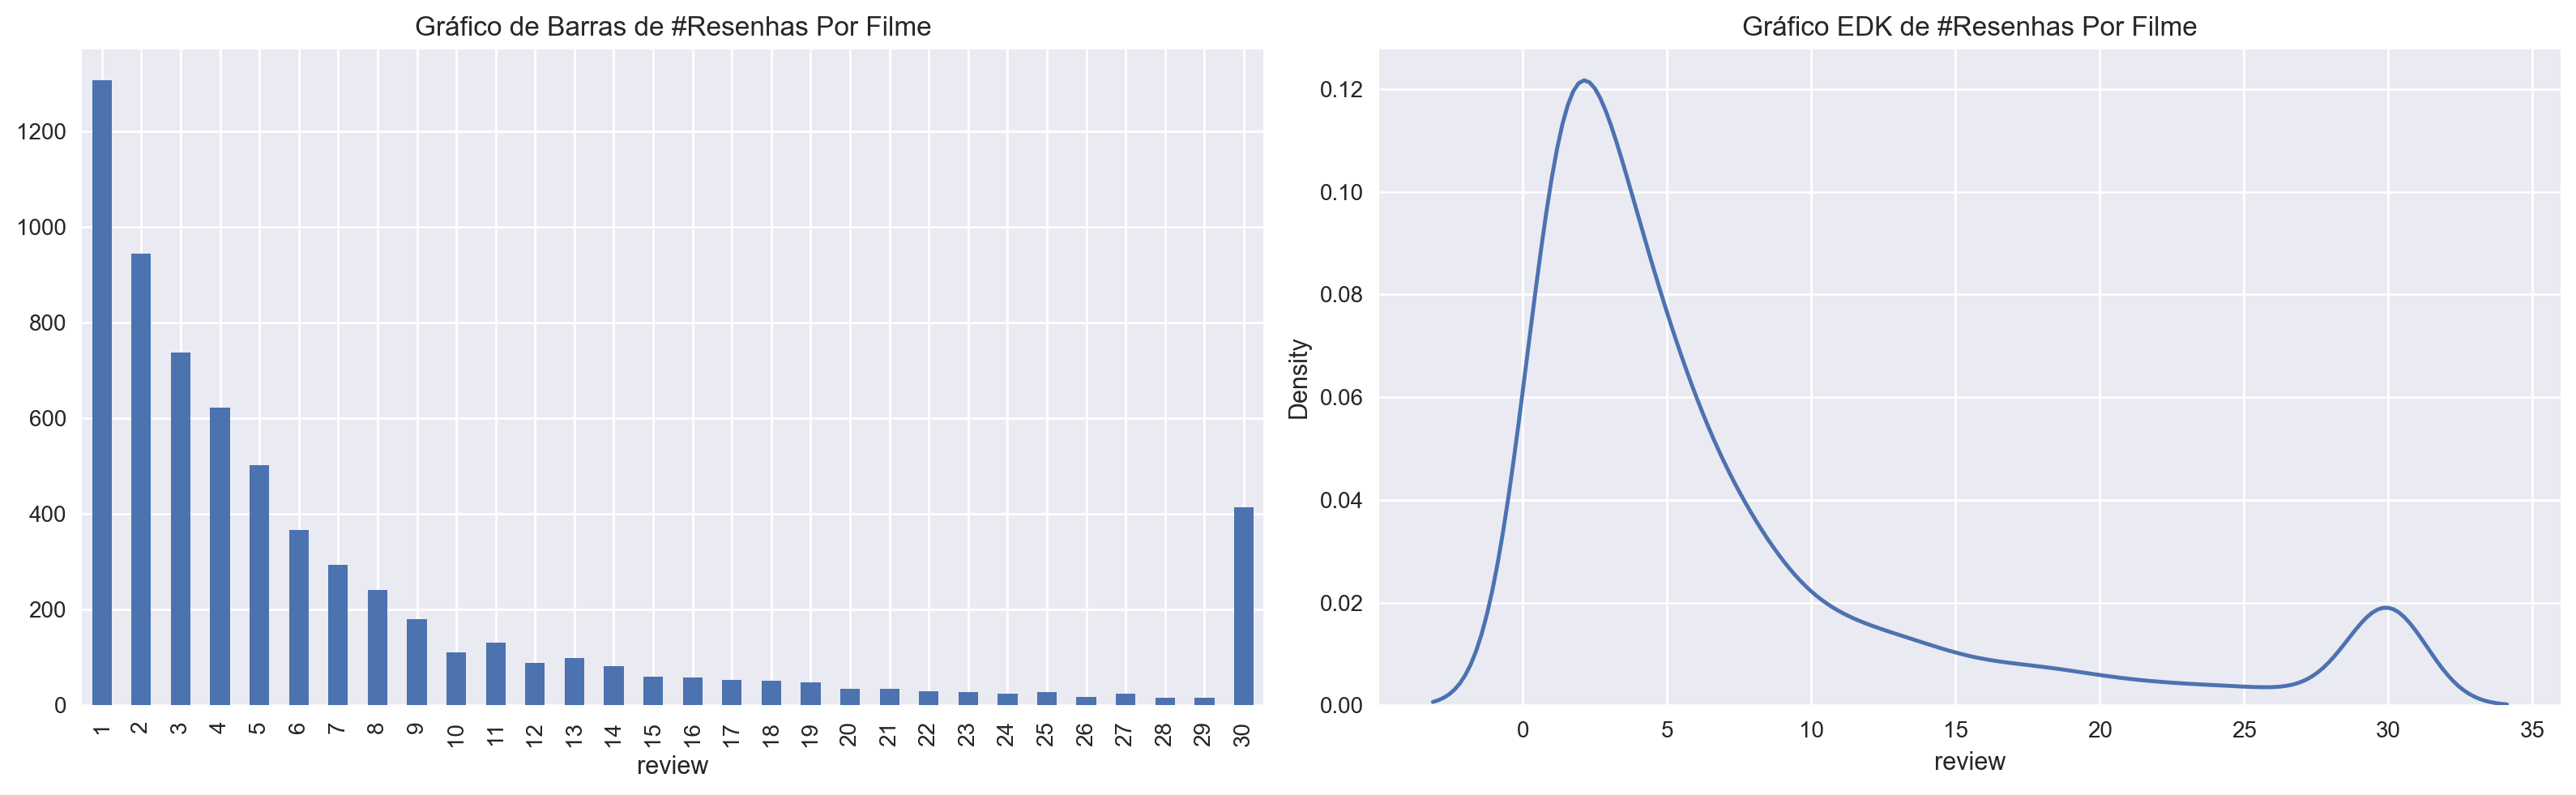

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de Barras de #Resenhas Por Filme')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico EDK de #Resenhas Por Filme')

fig.tight_layout()

### Class Balance

In [7]:
df_reviews['pos'].value_counts()

pos
0    23715
1    23616
Name: count, dtype: int64

### Rating Distribution in the Training and Test Sets

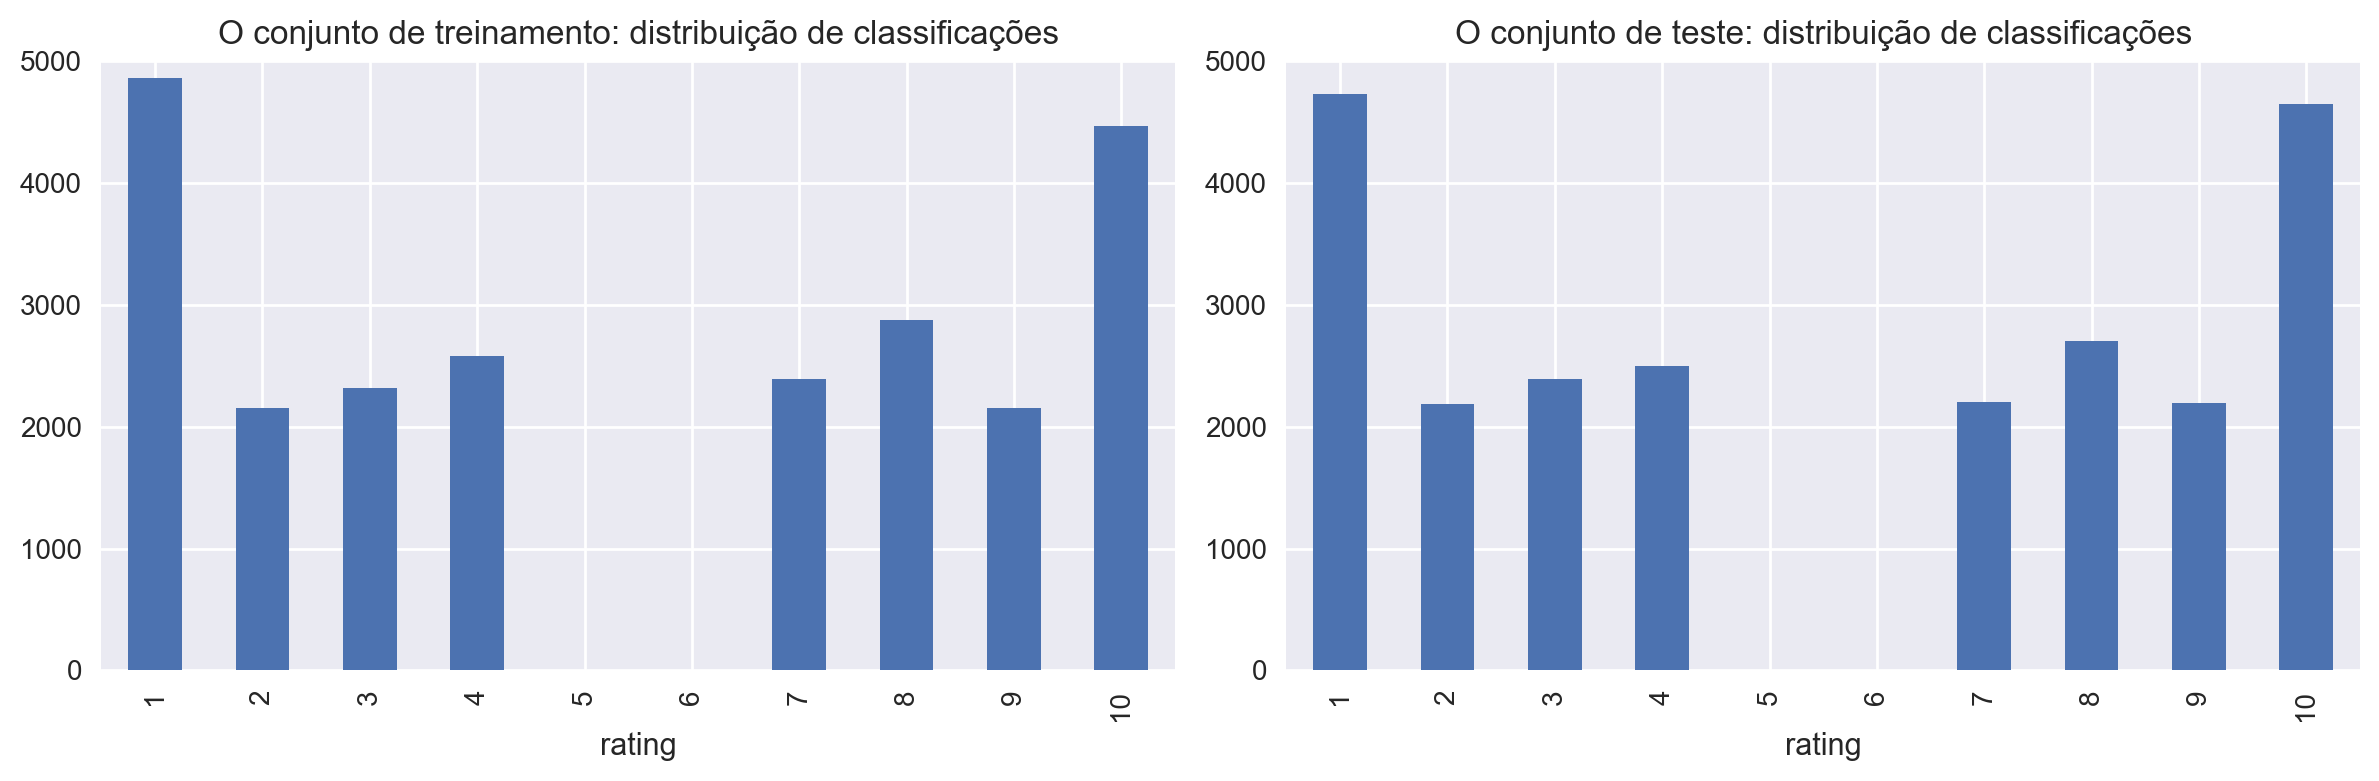

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de treinamento: distribuição de classificações')

ax = axs[1]
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de teste: distribuição de classificações')

fig.tight_layout()

Distribution of negative and positive reviews over the years for the two parts of the dataset.

C:\Users\luiiz\AppData\Local\Temp\ipykernel_20176\1483671763.py:14: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
C:\Users\luiiz\AppData\Local\Temp\ipykernel_20176\1483671763.py:15: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
C:\Users\luiiz\AppData\Local\Temp\ipykernel_20176\1483671763.py:30: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
C:\Users\luiiz\AppData\Local\Temp\ipykernel_20176\1483671763.py:31: UserWarning: 

Support for a

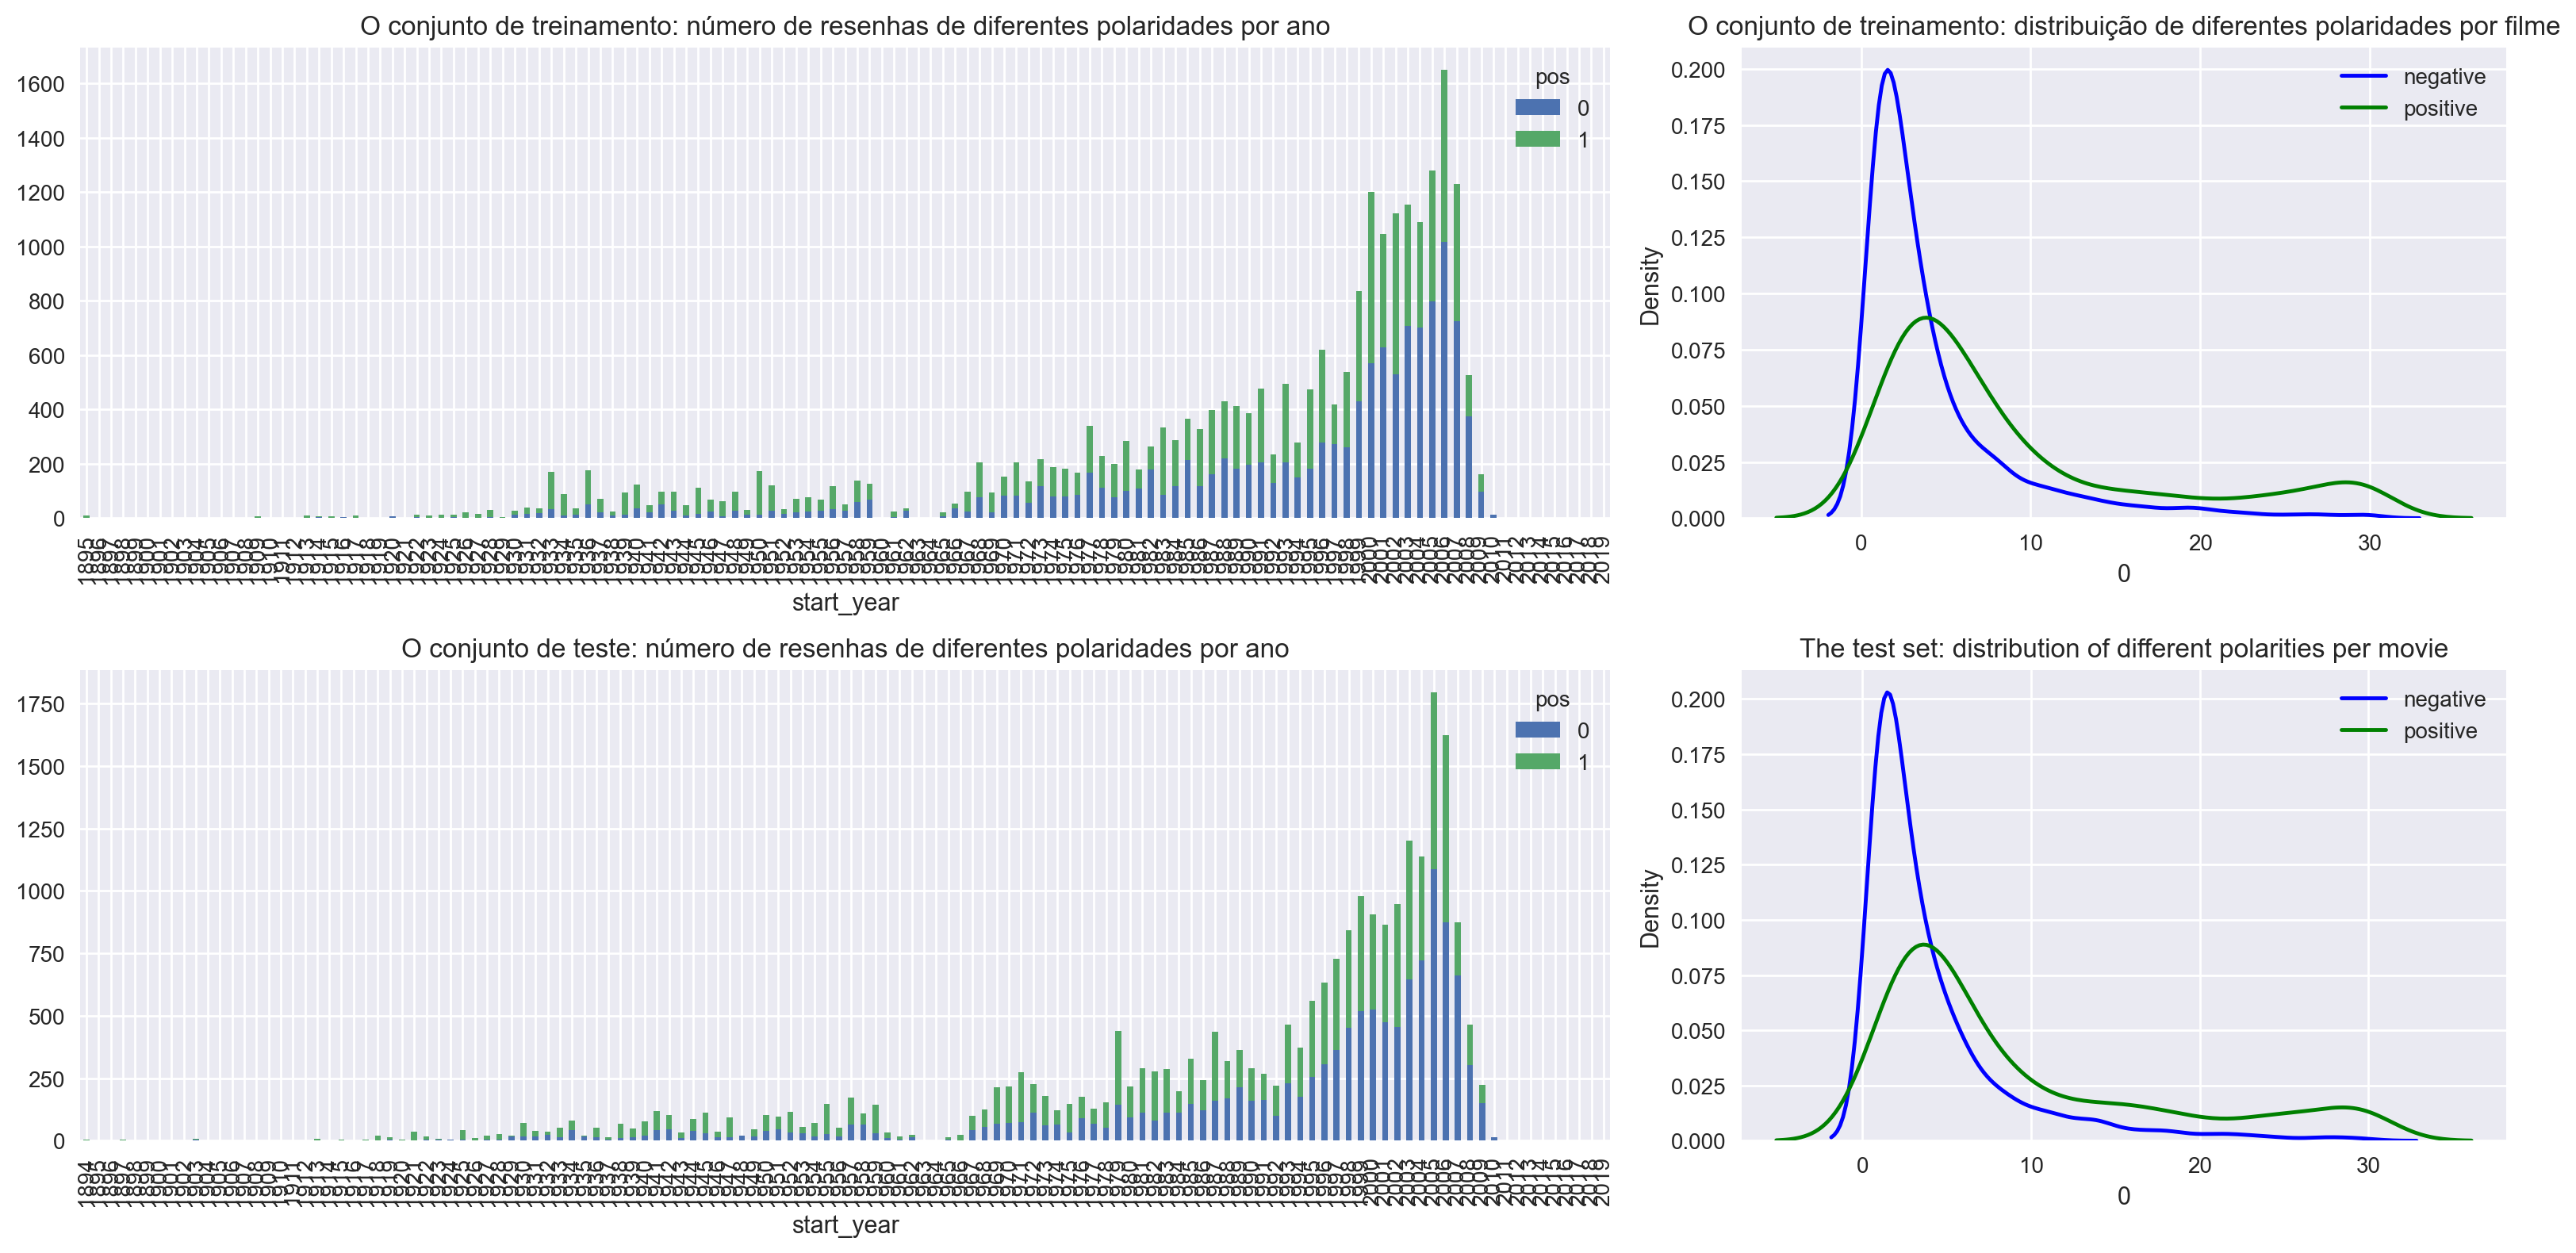

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1)))

ax = axs[0][0]

dft = df_reviews.query('ds_part == "train"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('O conjunto de treinamento: número de resenhas de diferentes polaridades por ano')

ax = axs[0][1]

dft = df_reviews.query('ds_part == "train"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('O conjunto de treinamento: distribuição de diferentes polaridades por filme')

ax = axs[1][0]

dft = df_reviews.query('ds_part == "test"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('O conjunto de teste: número de resenhas de diferentes polaridades por ano')

ax = axs[1][1]

dft = df_reviews.query('ds_part == "test"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('The test set: distribution of different polarities per movie')

fig.tight_layout()

The exploratory analysis shows that the dataset is well balanced between negative and positive reviews (23,715 vs. 23,616). The two classes have very similar sizes in both the training and the test sets, so no balancing technique such as upsampling or downsampling was needed.

The dataset also comes with a predefined train/test split in the `ds_part` column, so there is no need to create a new split manually.

## Evaluation Procedure

A single evaluation routine is used for all models. For the training and test sets, it reports accuracy, F1-score, average precision (APS) and ROC-AUC, and it plots F1-score versus decision threshold, the ROC curve and the precision-recall curve.

In [10]:
def evaluate_model(model, train_features, train_target, test_features, test_target):
    
    eval_stats = {}
    
    fig, axs = plt.subplots(1, 3, figsize=(20, 6)) 
    
    for type, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):
        
        eval_stats[type] = {}
    
        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]
        
        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]
        
        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba)
        roc_auc = metrics.roc_auc_score(target, pred_proba)    
        eval_stats[type]['ROC AUC'] = roc_auc

        # Precision-recall curve
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps
        
        if type == 'train':
            color = 'blue'
        else:
            color = 'green'

        # F1 score
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # mark selected thresholds
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'Valor F1') 

        # ROC
        ax = axs[1]    
        ax.plot(fpr, tpr, color=color, label=f'{type}, ROC AUC={roc_auc:.2f}')
        # setting crosses for some thresholds
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'            
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')        
        ax.set_title(f'Curva ROC')
        
        # Precision-recall curve
        ax = axs[2]
        ax.plot(recall, precision, color=color, label=f'{type}, AP={aps:.2f}')
        # mark selected thresholds
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')        

        eval_stats[type]['Accuracy'] = metrics.accuracy_score(target, pred_target)
        eval_stats[type]['F1'] = metrics.f1_score(target, pred_target)
    
    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Accuracy', 'F1', 'APS', 'ROC AUC'))
    
    print(df_eval_stats)
    
    return

## Text Normalization

All models below expect lowercase text without digits, punctuation or other non-letter characters.

In [11]:
def remover_acentos(texto):
    texto = unicodedata.normalize('NFKD', texto)
    texto = ''.join([char for char in texto if not unicodedata.combining(char)])
    return texto

df_reviews['review_norm'] = df_reviews['review'].str.lower()
df_reviews['review_norm'] = df_reviews['review_norm'].apply(remover_acentos)
df_reviews['review_norm'] = df_reviews['review_norm'].str.replace(r'[^a-zA-Z\s]', ' ', regex=True)
df_reviews['review_norm'] = df_reviews['review_norm'].str.replace(r'\s+', ' ', regex=True)
df_reviews['review_norm'] = df_reviews['review_norm'].str.strip()

Text normalization standardizes the reviews before vectorization. The texts are converted to lowercase, accents are removed, every character that is not a letter or whitespace is replaced with a space, and repeated whitespace is collapsed.

This step reduces unnecessary variation in the text: for example, words written in uppercase and lowercase are treated as the same token by the model.

## Train / Test Split

The dataset is already divided into training and test parts, indicated by the `ds_part` column.

In [12]:
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

(23796, 18)
(23535, 18)


## Modeling

The model numbering follows the variable names used in the code (`model0`, `model1`, `model3` and `model4`).

### Model 0 — Constant Baseline

          train  test
Accuracy    0.5   0.5
F1          0.0   0.0
APS         0.5   0.5
ROC AUC     0.5   0.5


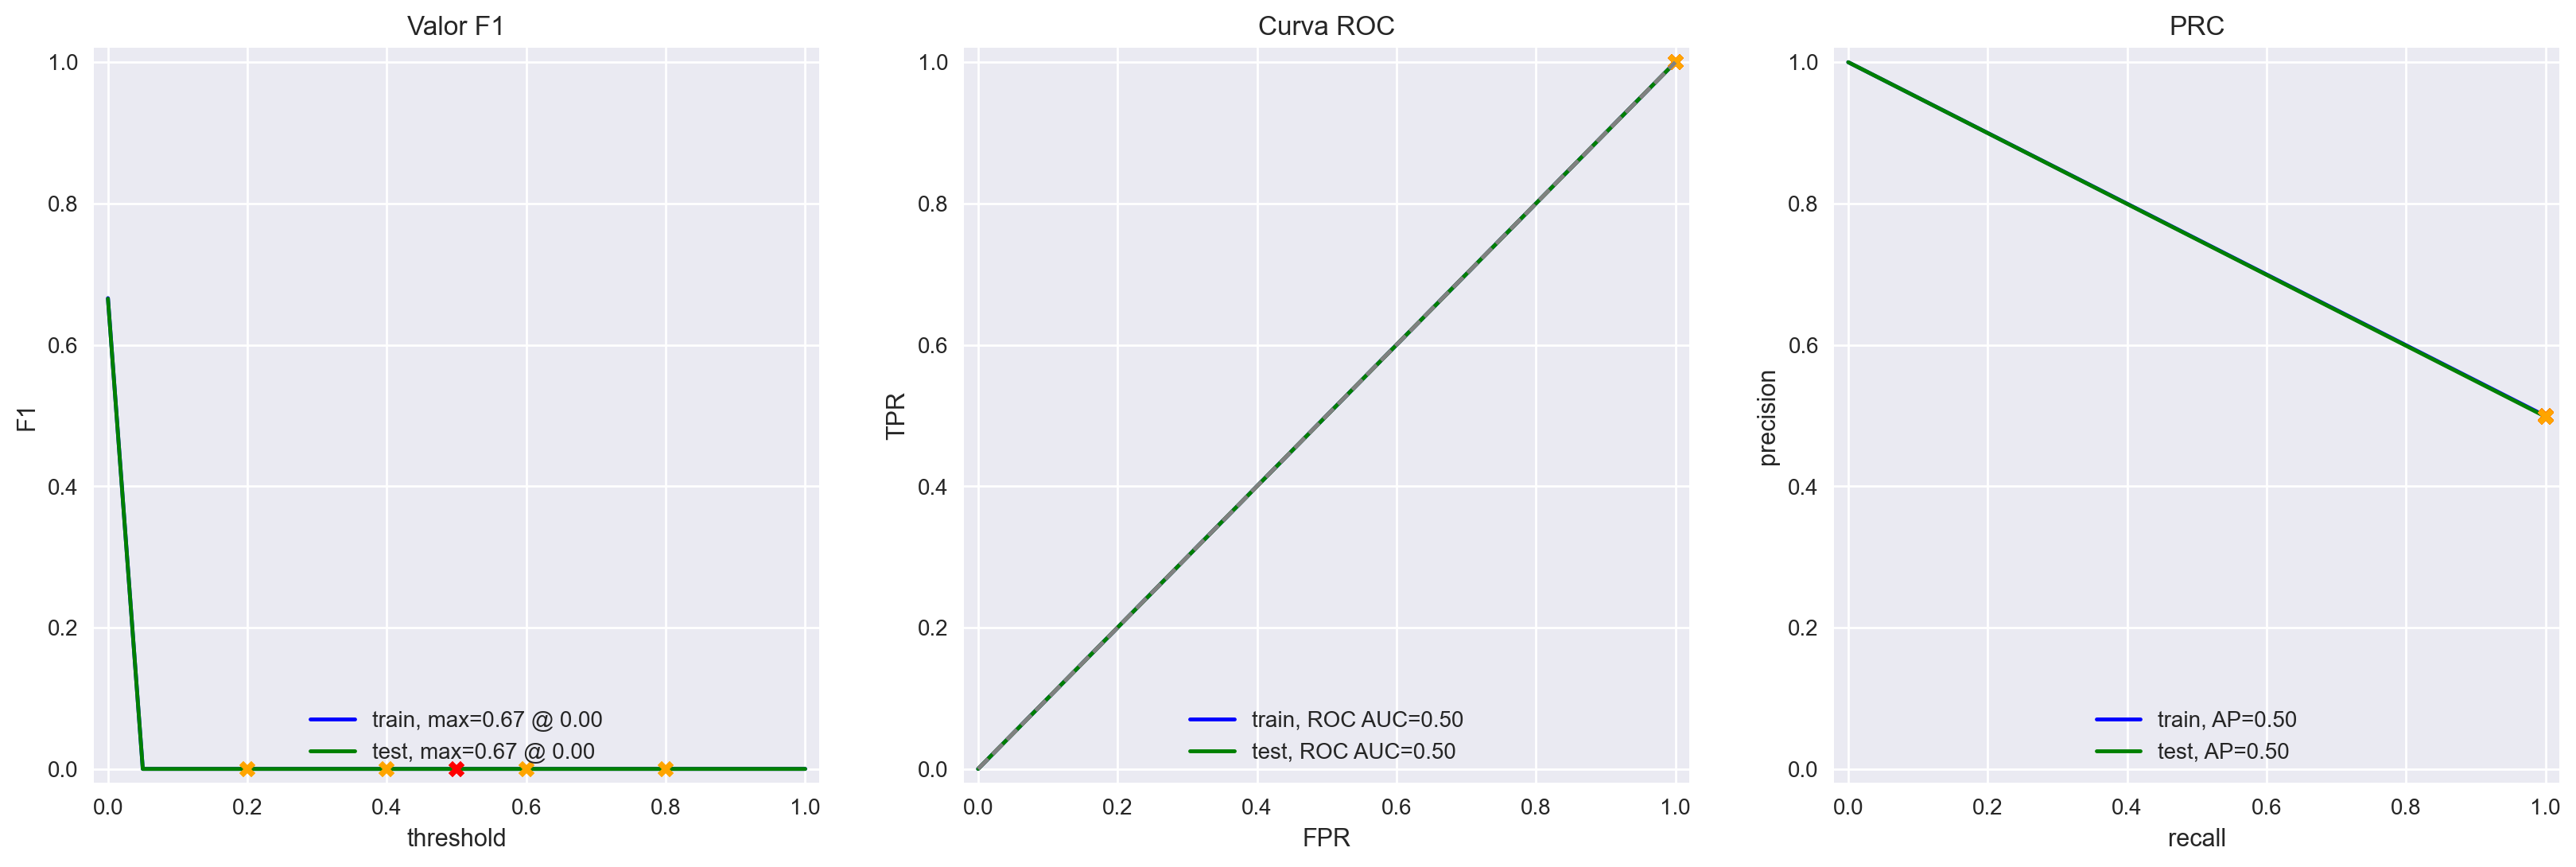

In [13]:
model0 = DummyClassifier(strategy='most_frequent', random_state=42)
model0.fit(df_reviews_train['review_norm'], df_reviews_train['pos'])

evaluate_model(
    model0,
    df_reviews_train['review_norm'],
    df_reviews_train['pos'],
    df_reviews_test['review_norm'],
    df_reviews_test['pos']
)

The `DummyClassifier` is used as a baseline. Because it ignores the text of the reviews and always predicts the most frequent class, its performance is limited (accuracy 0.50, F1 0.00). It serves only as a reference point for the TF-IDF-based models.

### Model 1 — NLTK Stop Words, TF-IDF and Logistic Regression

The normalized reviews are vectorized with TF-IDF, removing NLTK's English stop words, and classified with Logistic Regression.

          train  test
Accuracy   0.94  0.88
F1         0.94  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


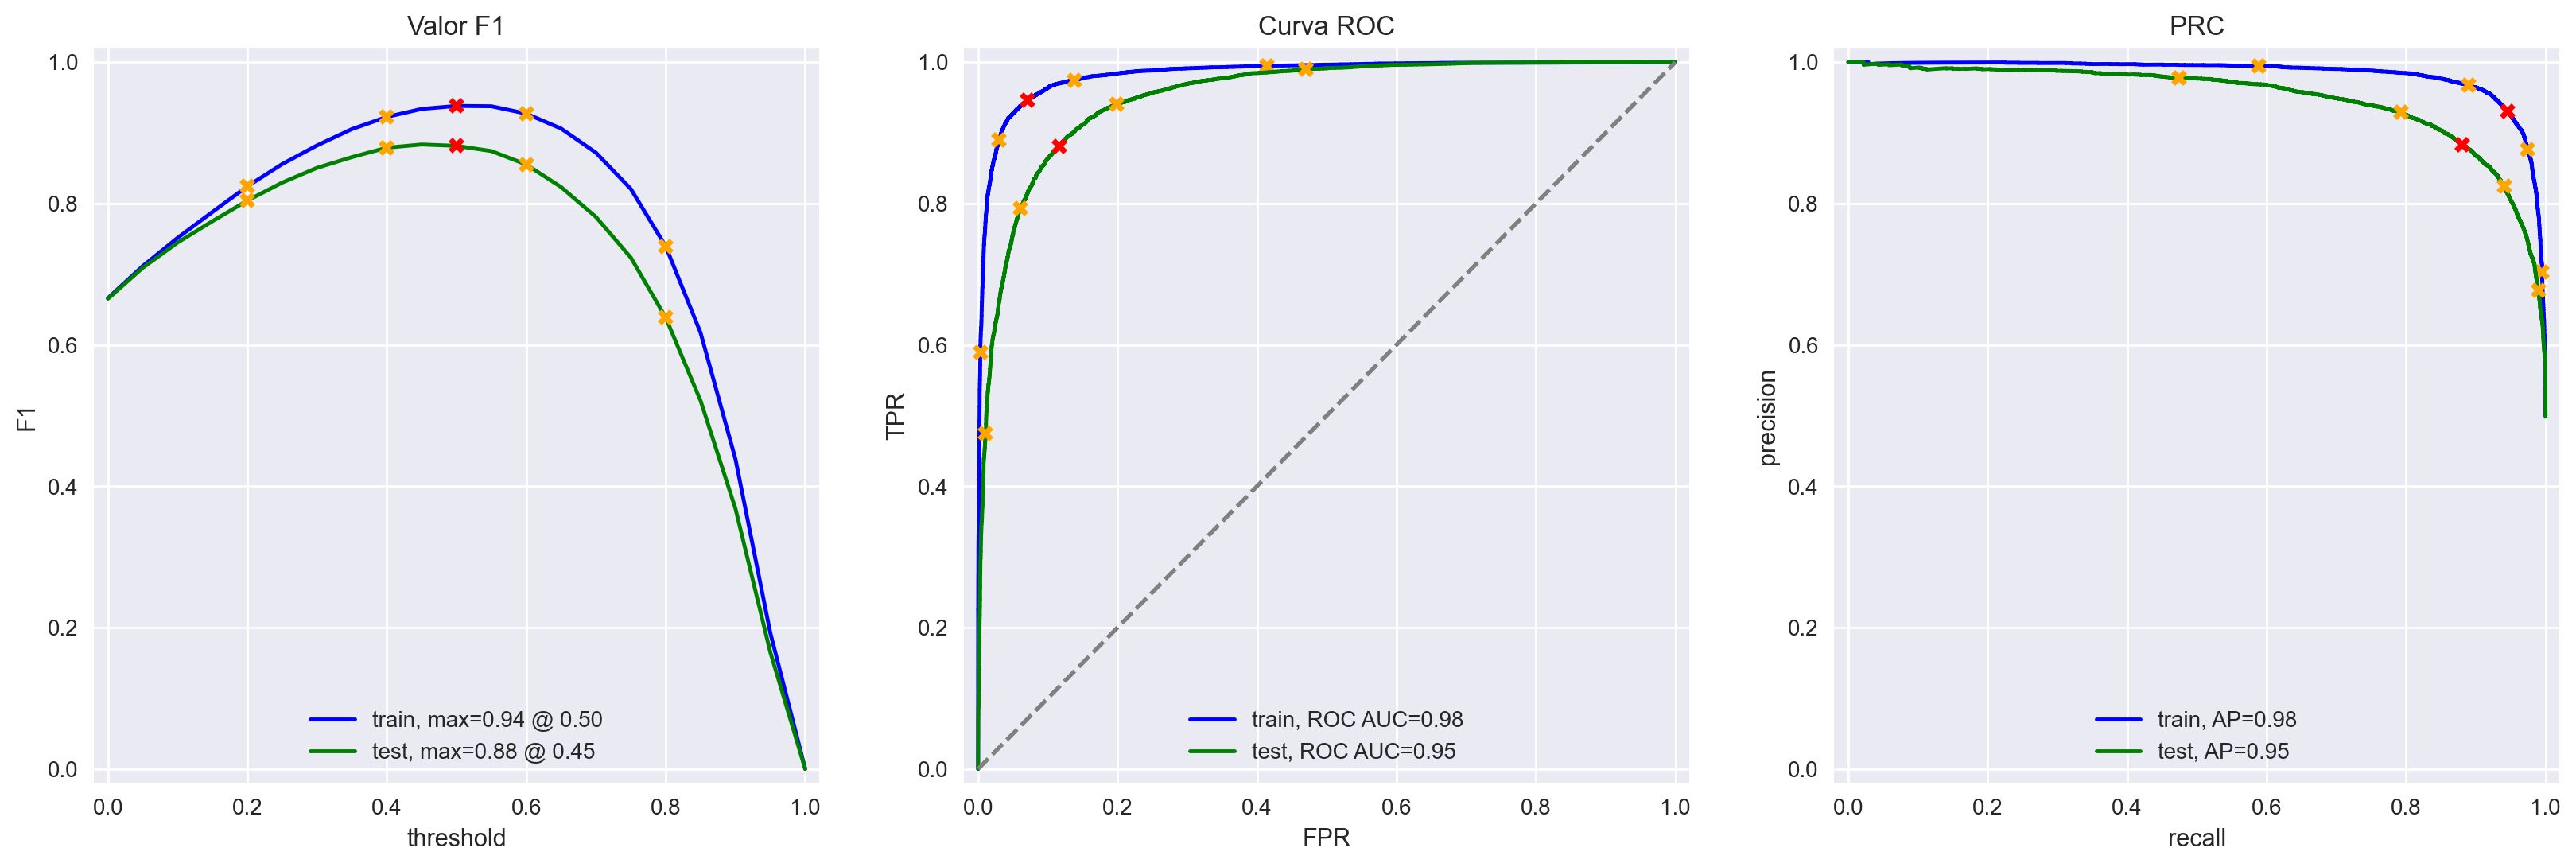

In [14]:
train_corpus = df_reviews_train['review_norm']
stop_words = list(stopwords.words('english'))

counter_vectorizer = TfidfVectorizer(stop_words=stop_words)
tf_idf1 = counter_vectorizer.fit_transform(train_corpus)

train_features1 = tf_idf1

test_corpus = df_reviews_test['review_norm']
test_features1 = counter_vectorizer.transform(test_corpus)

model1 = LogisticRegression(random_state=42)
model1.fit(train_features1, train_target)

pred_test = model1.predict(test_features1)

evaluate_model(model1, train_features1, train_target, test_features1, test_target)

Model 1 uses TF-IDF to transform the reviews into numeric vectors and Logistic Regression to classify them. It performs well, with an F1-score of about 0.88 and a ROC-AUC of about 0.95 on the test set.

Since the test F1-score is above 0.85, the model meets the project's minimum requirement. In addition, the gap between training (F1 0.94) and test performance is moderate, indicating good generalization.

### Model 3 — spaCy Lemmatization, TF-IDF and Logistic Regression

In [15]:
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

          train  test
Accuracy   0.93  0.88
F1         0.93  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


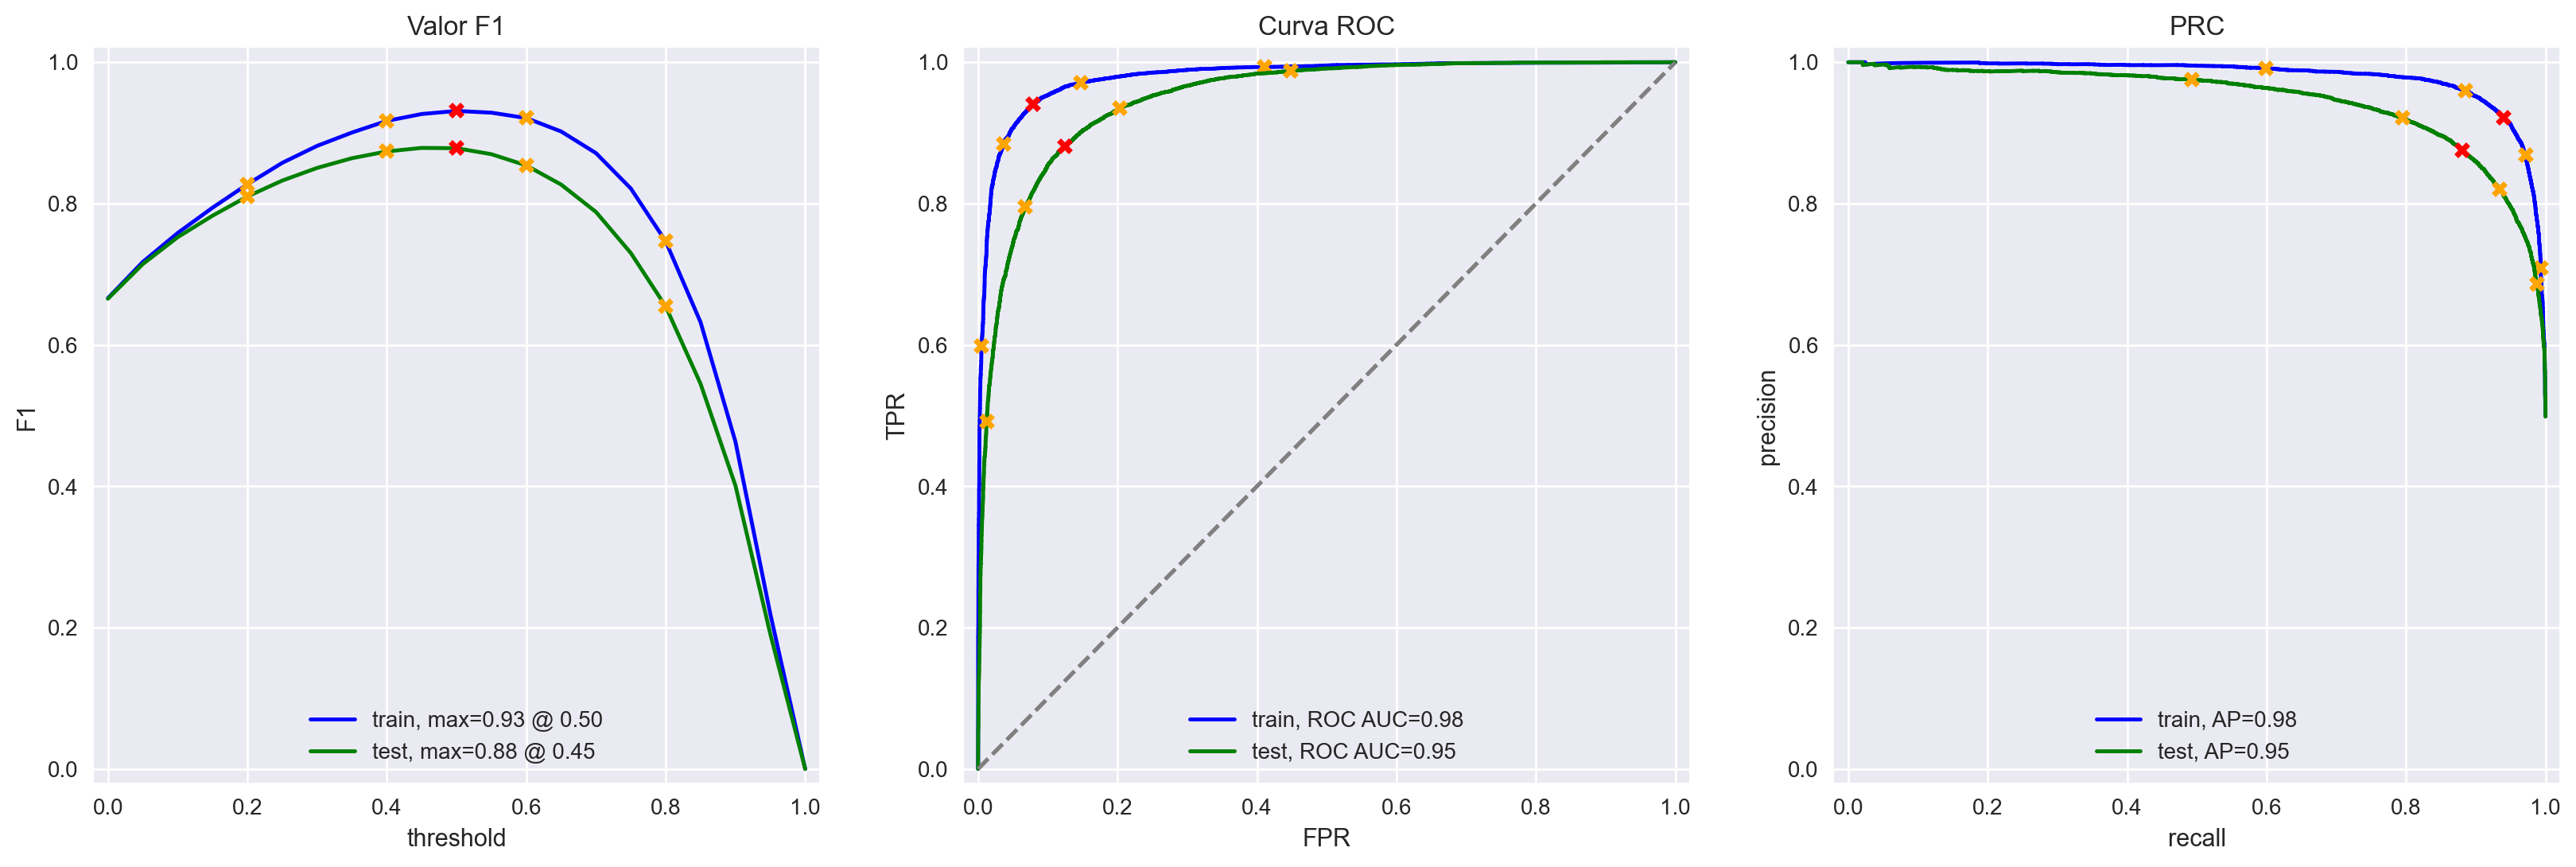

In [16]:
def text_preprocessing_3(text):
    
    doc = nlp(text)
    #tokens = [token.lemma_ for token in doc if not token.is_stop]
    tokens = [token.lemma_ for token in doc]
    
    return ' '.join(tokens)

train_corpus3 = df_reviews_train['review_norm'].apply(text_preprocessing_3)
test_corpus3 = df_reviews_test['review_norm'].apply(text_preprocessing_3)


counter_vectorizer3 = TfidfVectorizer(stop_words=stop_words)
tf_idf3 = counter_vectorizer3.fit_transform(train_corpus3)

train_features3 = tf_idf3
test_features3 = counter_vectorizer3.transform(test_corpus3)

model3 = LogisticRegression(random_state=42)
model3.fit(train_features3, train_target)

pred_test = model3.predict(test_features3)

evaluate_model(model3, train_features3, train_target, test_features3, test_target)


Model 3 adds a lemmatization step with spaCy (`en_core_web_sm`) before TF-IDF vectorization. The idea is to reduce inflected words to their base form, which decreases the size of the vocabulary.

Its performance is very similar to Model 1, also with a test F1-score of about 0.88. In this case, lemmatization did not bring a significant gain over simple normalization, although it remains a valid text preprocessing approach.

### Model 4 — spaCy Lemmatization, TF-IDF and LightGBM

[LightGBM] [Info] Number of positive: 11884, number of negative: 11912
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.152318 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 455729
[LightGBM] [Info] Number of data points in the train set: 23796, number of used features: 9348
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499412 -> initscore=-0.002353
[LightGBM] [Info] Start training from score -0.002353


c:\Users\luiiz\OneDrive\Documentos\TripleTen\Sprint14\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\luiiz\OneDrive\Documentos\TripleTen\Sprint14\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\luiiz\OneDrive\Documentos\TripleTen\Sprint14\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\luiiz\OneDrive\Documentos\TripleTen\Sprint14\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\luiiz\OneDrive\Documentos\TripleTen\Sprint14\venv\Lib\site-packages\sklearn\utils\v

          train  test
Accuracy   0.91  0.86
F1         0.91  0.86
APS        0.97  0.93
ROC AUC    0.97  0.94


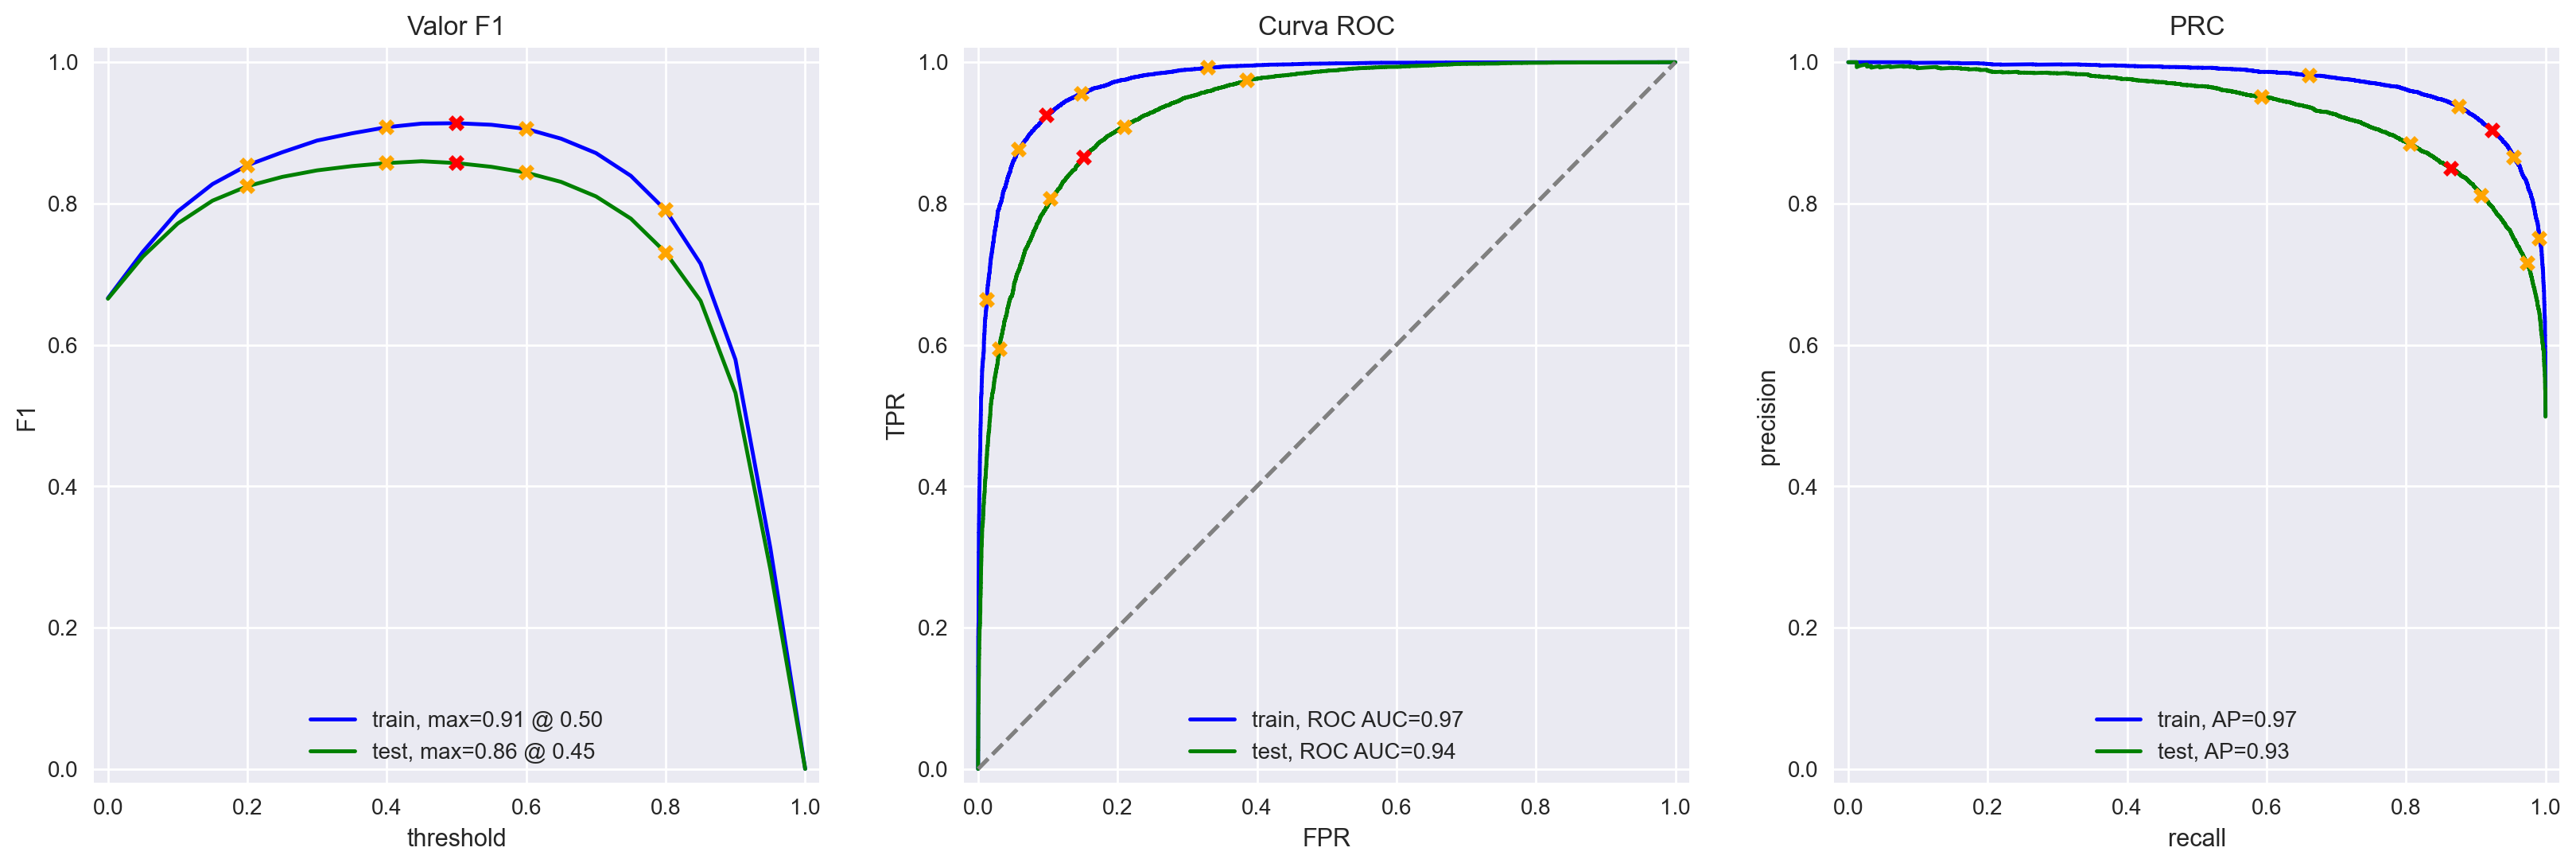

In [17]:
def text_preprocessing_4(text):
    
    doc = nlp(text)
    #tokens = [token.lemma_ for token in doc if not token.is_stop]
    tokens = [token.lemma_ for token in doc]
    
    return ' '.join(tokens)

train_corpus4 = df_reviews_train['review_norm'].apply(text_preprocessing_4)
test_corpus4 = df_reviews_test['review_norm'].apply(text_preprocessing_4)


counter_vectorizer4 = TfidfVectorizer(stop_words=stop_words)
tf_idf4 = counter_vectorizer4.fit_transform(train_corpus4)

train_features4 = tf_idf4
test_features4 = counter_vectorizer4.transform(test_corpus4)

model4 = LGBMClassifier(random_state=42)
model4.fit(train_features4, train_target)

pred_test = model4.predict(test_features4)

evaluate_model(model4, train_features4, train_target, test_features4, test_target)

Model 4 uses the same spaCy and TF-IDF preprocessing but replaces Logistic Regression with `LGBMClassifier`. It also meets the minimum requirement, with a test F1-score of about 0.86.

Despite the good performance, it is slightly below the Logistic Regression models. This suggests that, for this specific problem, the TF-IDF + Logistic Regression combination is both more effective and simpler.

### BERT (not implemented)

BERT was not used in the final solution, because computing BERT embeddings for tens of thousands of reviews is very expensive on a CPU and can take several hours. Since the TF-IDF-based models already exceed an F1-score of 0.85 on the test set, the lighter and computationally cheaper models were kept.

## Custom Reviews

A small set of hand-written reviews is used to sanity-check how the trained models behave on new text. The same normalization is applied before prediction, and each line shows the predicted probability that the review is positive.

In [23]:
# Hand-written example reviews used to sanity-check the trained models

my_reviews = pd.DataFrame([
    'I simply did not like this movie. It is not my kind of film.',
    'I was bored and fell asleep halfway through the movie.',
    'I was truly fascinated by this film.',
    'The actors looked tired and uninterested. This movie was a waste of money.',
    'I did not expect the new version to be this good. The writers really cared about the original material.',
    'The movie has its pros and cons, but overall it is a decent film. I would watch it again.',
    'What a terrible attempt at comedy. Not a single joke worked and everyone was annoying.',
    'Releasing it on Netflix was a bold move, and I really enjoyed watching this smart and exciting drama.'
], columns=['review'])

my_reviews['review_norm'] = my_reviews['review'].str.lower()
my_reviews['review_norm'] = my_reviews['review_norm'].apply(remover_acentos)
my_reviews['review_norm'] = my_reviews['review_norm'].str.replace(r'[^a-zA-Z\s]', ' ', regex=True)
my_reviews['review_norm'] = my_reviews['review_norm'].str.replace(r'\s+', ' ', regex=True)
my_reviews['review_norm'] = my_reviews['review_norm'].str.strip()

my_reviews

,review,review_norm
0,I simply did not like this movie. It is not my...,i simply did not like this movie it is not my ...
1,I was bored and fell asleep halfway through th...,i was bored and fell asleep halfway through th...
2,I was truly fascinated by this film.,i was truly fascinated by this film
3,The actors looked tired and uninterested. This...,the actors looked tired and uninterested this ...
4,I did not expect the new version to be this go...,i did not expect the new version to be this go...
5,"The movie has its pros and cons, but overall i...",the movie has its pros and cons but overall it...
6,What a terrible attempt at comedy. Not a singl...,what a terrible attempt at comedy not a single...
7,"Releasing it on Netflix was a bold move, and I...",releasing it on netflix was a bold move and i ...


### Model 1

In [24]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model1.predict_proba(counter_vectorizer.transform(texts))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.18:  i simply did not like this movie it is not my kind of film
0.07:  i was bored and fell asleep halfway through the movie
0.73:  i was truly fascinated by this film
0.02:  the actors looked tired and uninterested this movie was a waste of money
0.22:  i did not expect the new version to be this good the writers really cared about the original materia
0.42:  the movie has its pros and cons but overall it is a decent film i would watch it again
0.01:  what a terrible attempt at comedy not a single joke worked and everyone was annoying
0.73:  releasing it on netflix was a bold move and i really enjoyed watching this smart and exciting drama


### Model 3

In [25]:
texts = my_reviews['review_norm']

texts_spacy = texts.apply(text_preprocessing_3)

my_reviews_pred_prob = model3.predict_proba(counter_vectorizer3.transform(texts_spacy))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.24:  i simply did not like this movie it is not my kind of film
0.07:  i was bored and fell asleep halfway through the movie
0.76:  i was truly fascinated by this film
0.00:  the actors looked tired and uninterested this movie was a waste of money
0.19:  i did not expect the new version to be this good the writers really cared about the original materia
0.40:  the movie has its pros and cons but overall it is a decent film i would watch it again
0.02:  what a terrible attempt at comedy not a single joke worked and everyone was annoying
0.92:  releasing it on netflix was a bold move and i really enjoyed watching this smart and exciting drama


### Model 4

In [26]:
texts = my_reviews['review_norm']

texts_spacy = texts.apply(text_preprocessing_4)

my_reviews_pred_prob = model4.predict_proba(counter_vectorizer4.transform(texts_spacy))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.62:  i simply did not like this movie it is not my kind of film
0.39:  i was bored and fell asleep halfway through the movie
0.68:  i was truly fascinated by this film
0.05:  the actors looked tired and uninterested this movie was a waste of money
0.60:  i did not expect the new version to be this good the writers really cared about the original materia
0.51:  the movie has its pros and cons but overall it is a decent film i would watch it again
0.05:  what a terrible attempt at comedy not a single joke worked and everyone was annoying
0.81:  releasing it on netflix was a bold move and i really enjoyed watching this smart and exciting drama


c:\Users\luiiz\OneDrive\Documentos\TripleTen\Sprint14\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


On the hand-written reviews, Model 1 behaves consistently. Clearly negative reviews receive a low probability of being positive, while clearly positive reviews receive higher probabilities. The review with more ambiguous language, mentioning both pros and cons, receives an intermediate probability (0.42), indicating lower confidence on texts with mixed sentiment.

## Conclusions

Several models were trained to classify IMDB movie reviews as positive or negative. The exploratory analysis showed that the classes are well balanced in both the training and the test sets, so no balancing technique was required.

The texts were normalized and transformed into numeric vectors with TF-IDF. The `DummyClassifier` baseline performed poorly, as expected, since it does not use the content of the reviews.

| Model | Test accuracy | Test F1 | Test APS | Test ROC-AUC |
|---|---|---|---|---|
| Model 0 — Dummy (most frequent) | 0.50 | 0.00 | 0.50 | 0.50 |
| Model 1 — NLTK + TF-IDF + Logistic Regression | 0.88 | **0.88** | 0.95 | 0.95 |
| Model 3 — spaCy + TF-IDF + Logistic Regression | 0.88 | **0.88** | 0.95 | 0.95 |
| Model 4 — spaCy + TF-IDF + LightGBM | 0.86 | 0.86 | 0.93 | 0.94 |

The best performance was obtained with TF-IDF and Logistic Regression, which reached an F1-score of about 0.88 and a ROC-AUC of about 0.95 on the test set. The model with spaCy lemmatization, TF-IDF and Logistic Regression produced practically the same result, while the LightGBM model also exceeded the minimum threshold but performed slightly worse.

The main objective of the project was therefore achieved, since more than one model exceeded an F1-score of 0.85 on the test set. Model 1 is the recommended solution, as it combines good performance, simplicity and lower computational cost.